# Growth across all recorded recipients

How did funding, requests and funding per request change across 2020-2025?

**Scope:** All recorded recipients in the cleaned data, with no legal-form or top-1% selection. This differs from [notebook 07](07_growth_drivers_analysis.ipynb), which retains legal forms observed in 2025. The population changes over time; absence does not mean zero funding or closure.

Annual growth requires consecutive years; whole-period growth uses fixed 2020 and 2025 endpoints. Percentage growth requires a positive starting amount, while zero endings remain valid declines of 100%. Log growth requires both amounts to be positive. Each measure reports its available sample. Amounts are nominal and requests are not necessarily unique supporters.

The [methodology](../METHODOLOGY.md) documents the source corrections. This notebook is descriptive, not evidence of causal drivers or individual supporter income.

## Data inputs and validation

The notebook loads its own cleaned funding records, checks identifiers and numerical values, and applies only the analysis-period restriction. Missing amounts remain missing; duplicate recipient-year keys stop execution rather than being combined. A total is unavailable if any contributing value is missing.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src').is_dir():
    raise RuntimeError('Run from the project root or notebooks directory.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from chart_style import load_chart_style, apply_chart_style, colors_from_style, finish_chart
from growth_analysis import build_growth_analysis
from growth_components import compare_growth_components

style = load_chart_style(PROJECT_ROOT)
apply_chart_style(style)
CHART_COLORS = colors_from_style(style)
START, END = 2020, 2025
YEARS = list(range(START, END + 1))
source = pd.read_csv(PROJECT_ROOT / 'data/interim/vmi_support_by_recipient.csv',
                     dtype={'recipient_code': 'string'}, low_memory=False)
year = pd.to_numeric(source['tax_year'], errors='coerce')
if (year.isna() | ~np.isfinite(year) | year.mod(1).ne(0)).any():
    raise ValueError('Missing or invalid tax years require review.')
source['tax_year'] = year.astype(int)
data = source.loc[source['tax_year'].isin(YEARS)].copy()
data['recipient_code'] = data['recipient_code'].str.strip()
if (data['recipient_code'].isna() | data['recipient_code'].eq('')).any():
    raise ValueError('Missing recipient codes require review.')
if data.duplicated(['recipient_code', 'tax_year']).any():
    raise ValueError('Duplicate recipient-year records require review.')
if set(data['tax_year']) != set(YEARS):
    raise ValueError('An expected analysis year is missing.')
for column in ['requests', 'calculated_pmd_eur']:
    raw = data[column]
    values = pd.to_numeric(raw, errors='coerce')
    invalid = (raw.notna() & values.isna()) | (values.notna() & ~np.isfinite(values)) | values.lt(0)
    if column == 'requests':
        invalid |= values.notna() & values.mod(1).ne(0)
    if invalid.any():
        raise ValueError(f'Invalid {column} values require review.')
    data[column] = values

def complete_total(s):
    return s.sum(min_count=max(1, len(s)))

def euros(value):
    return f'{value:,.2f}'.rstrip('0').rstrip('.') + ' EUR'

annual, fixed = build_growth_analysis(data, start=START, end=END)
assert len(annual) == len(data)
coverage = annual.groupby('tax_year').agg(
    recorded_recipients=('recipient_code', 'nunique'),
    known_funding=('amount', 'count'), known_requests=('requests', 'count'))
print(f'All recorded recipients: {data.recipient_code.nunique():,}; records: {len(data):,}. No legal-form filter.')
display(coverage.style.format('{:,.0f}'))

All recorded recipients: 30,779; records: 120,734. No legal-form filter.


,recorded_recipients,known_funding,known_requests
tax_year,,,
2020,"23,240","23,240","23,240"
2021,"22,798","22,798","22,798"
2022,"22,147","22,147","22,147"
2023,"22,555","22,555","22,555"
2024,"14,511","14,511","14,511"
2025,"15,483","15,483","15,483"


## Annual funding and request totals

These totals include every recorded recipient in each year, not a fixed set of organizations. Overall funding per request divides total funding by total requests; it is not the median of individual requests.

,funding,requests,average_per_request,funding_growth,requests_growth,average_per_request_growth
tax_year,,,,,,
2020,"21,654,753.19 EUR","560,324",38.65 EUR,Unavailable,Unavailable,Unavailable
2021,"27,843,175.86 EUR","604,259",46.08 EUR,+28.6%,+7.8%,+19.2%
2022,"29,202,852.2 EUR","574,934",50.79 EUR,+4.9%,-4.9%,+10.2%
2023,"33,985,135.12 EUR","597,309",56.9 EUR,+16.4%,+3.9%,+12.0%
2024,"36,904,168.23 EUR","591,434",62.4 EUR,+8.6%,-1.0%,+9.7%
2025,"40,124,624.74 EUR","652,119",61.53 EUR,+8.7%,+10.3%,-1.4%


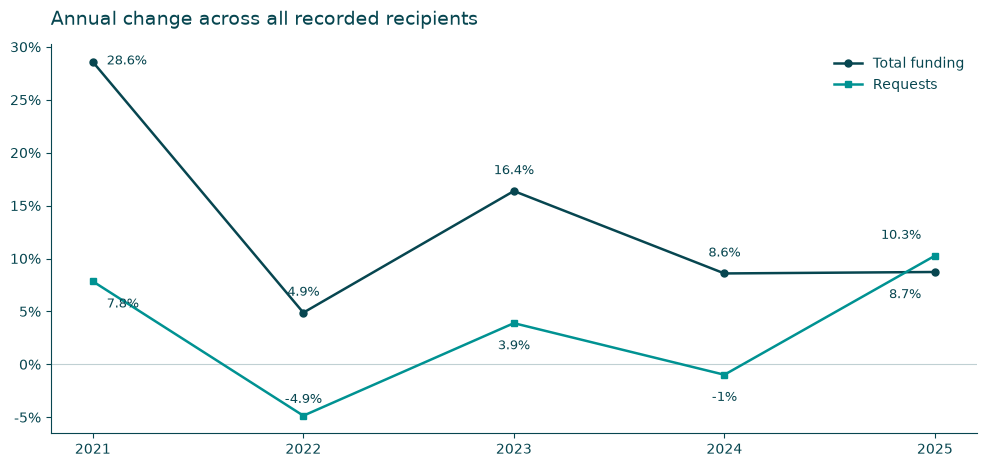

In [2]:
totals = annual.groupby('tax_year').agg(
    funding=('amount', complete_total), requests=('requests', complete_total))
totals['average_per_request'] = totals['funding'] / totals['requests'].where(totals['requests'] > 0)
for column in ['funding', 'requests', 'average_per_request']:
    previous = totals[column].shift()
    totals[column + '_growth'] = totals[column] / previous.where(previous > 0) - 1
display(totals.style.format({
    'funding': euros, 'requests': '{:,.0f}', 'average_per_request': euros,
    **{c: '{:+.1%}' for c in totals if c.endswith('_growth')},
}, na_rep='Unavailable'))
fig, ax = plt.subplots(figsize=(10, 5))
for column, label, color, marker in [
    ('funding_growth', 'Total funding', CHART_COLORS['primary'], 'o'),
    ('requests_growth', 'Requests', CHART_COLORS['secondary'], 's'),
]:
    ax.plot(totals.index, totals[column], label=label, color=color, marker=marker)
ax.set_title('Annual change across all recorded recipients')
ax.set_xticks(YEARS[1:])
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:.0%}'))
ax.grid(False, which='both')
ax.legend(frameon=False)
finish_chart(fig)

## Consecutive-year recipient growth

Each row compares the same recipient across two consecutive calendar years. Coverage distinguishes absent records, missing funding, zero starting funding and valid percentage growth. The denominator for increase/decrease shares is the comparable sample, not everyone recorded anywhere in the six years.

Status,Available,Missing record at an endpoint,Zero starting funding
Period,,,
2020-2021,"20,908","9,805",66
2021-2022,"20,222","10,501",56
2022-2023,"19,931","10,780",68
2023-2024,"12,632","18,111",36
2024-2025,"13,375","17,365",39


,Comparable recipients,Increasing share,Decreasing share,Unchanged share,Median euro change,P25 growth,Median growth,P75 growth
Period,,,,,,,,
2020-2021,"20,908",58.8%,41.2%,0.0%,13.85 EUR,-17.8%,7.7%,39.1%
2021-2022,"20,222",54.7%,45.3%,0.0%,9.31 EUR,-24.1%,4.8%,39.2%
2022-2023,"19,931",55.8%,44.2%,0.0%,12.55 EUR,-22.7%,6.0%,41.4%
2023-2024,"12,632",66.2%,33.8%,0.0%,88.11 EUR,-12.0%,21.8%,74.1%
2024-2025,"13,375",54.0%,46.0%,0.0%,15.98 EUR,-24.8%,4.6%,41.2%


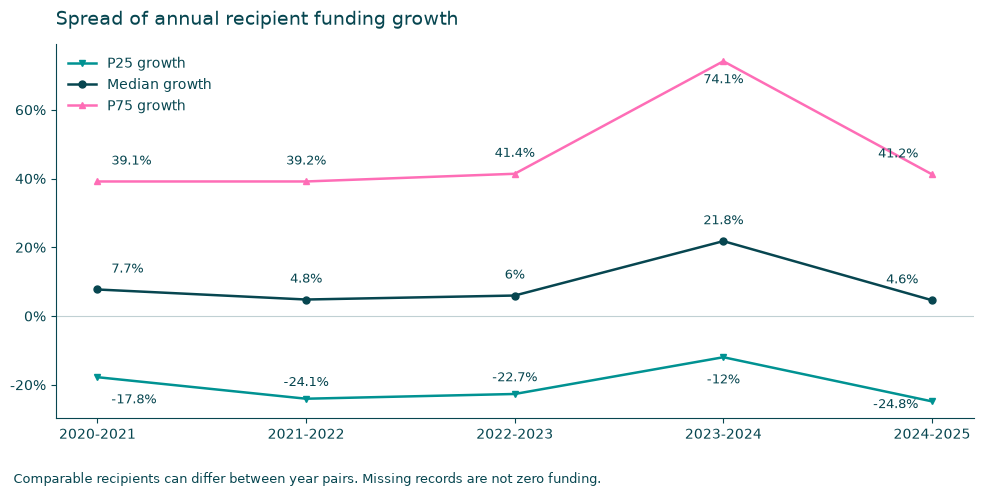

In [3]:
funding_matrix = annual.pivot(index='recipient_code', columns='tax_year', values='amount').reindex(columns=YEARS)
presence = annual.assign(present=True).pivot(index='recipient_code', columns='tax_year', values='present').reindex(columns=YEARS).fillna(False)
growth_rows, coverage_rows = [], []
for end in YEARS[1:]:
    start = end - 1
    a, b = funding_matrix[start], funding_matrix[end]
    both = presence[start] & presence[end]
    status = pd.Series('Missing record at an endpoint', index=funding_matrix.index)
    status.loc[both & (a.isna() | b.isna())] = 'Missing funding value'
    status.loc[both & a.notna() & b.notna() & a.eq(0)] = 'Zero starting funding'
    valid = both & a.gt(0) & b.ge(0)
    status.loc[valid] = 'Available'
    for label, count in status.value_counts().items():
        coverage_rows.append({'Period': f'{start}-{end}', 'Status': label, 'Recipients': count})
    pct = (b / a.where(a > 0) - 1).loc[valid]
    delta = (b-a).loc[valid]
    growth_rows.append({'Period': f'{start}-{end}', 'Comparable recipients': len(pct),
        'Increasing share': pct.gt(0).mean(), 'Decreasing share': pct.lt(0).mean(),
        'Unchanged share': pct.eq(0).mean(), 'Median euro change': delta.median(),
        'P25 growth': pct.quantile(.25), 'Median growth': pct.median(), 'P75 growth': pct.quantile(.75)})
annual_coverage = pd.DataFrame(coverage_rows)
annual_growth = pd.DataFrame(growth_rows).set_index('Period')
display(annual_coverage.pivot(index='Period', columns='Status', values='Recipients').fillna(0).style.format('{:,.0f}'))
display(annual_growth.style.format({
    'Comparable recipients': '{:,.0f}', 'Median euro change': euros,
    **{c: '{:.1%}' for c in annual_growth if 'share' in c or 'growth' in c},
}, na_rep='Unavailable'))
fig, ax = plt.subplots(figsize=(10, 5))
for column, color, marker in [('P25 growth', CHART_COLORS['secondary'], 'v'),
                              ('Median growth', CHART_COLORS['primary'], 'o'),
                              ('P75 growth', CHART_COLORS['accent'], '^')]:
    ax.plot(annual_growth.index, annual_growth[column], label=column, color=color, marker=marker)
ax.set_title('Spread of annual recipient funding growth')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:.0%}'))
ax.grid(False, which='both')
ax.legend(frameon=False)
finish_chart(fig, 'Comparable recipients can differ between year pairs. Missing records are not zero funding.')

## Fixed 2020-2025 growth

Whole-period percentage growth uses known 2020 and 2025 funding and a positive 2020 amount. A fall to zero is -100% growth, but has no defined log growth. Recipients observed only in intermediate years remain in coverage counts, not in the growth sample.

In [4]:
display(fixed['fixed_period_status'].value_counts().rename_axis('Status').to_frame('Recipients'))
valid_fixed = fixed.loc[fixed['fixed_period_status'].eq('Available')].copy()
fixed_description = pd.DataFrame({
    'Percentage growth': valid_fixed['fixed_period_growth_pct'].describe(percentiles=[.25, .5, .75, .9])})
display(fixed_description.style.format({'Percentage growth': '{:.1%}'},
    subset=pd.IndexSlice[fixed_description.index != 'count', :], na_rep='Unavailable')
    .format('{:,.0f}', subset=pd.IndexSlice[['count'], :]))
print(f'Valid percentage-growth recipients: {len(valid_fixed):,}')
print(f'Valid log-growth recipients: {valid_fixed.fixed_period_log_growth.notna().sum():,}')
print(f'Positive-start recipients ending at zero: {valid_fixed.endpoint_amount.eq(0).sum():,}')
columns = ['recipient_code', 'recipient_name', 'baseline_amount', 'endpoint_amount', 'fixed_period_growth_pct']
for title, subset in [
    ('Largest proportional increases', valid_fixed.loc[valid_fixed.fixed_period_growth_pct > 0].nlargest(10, 'fixed_period_growth_pct')),
    ('Strongest proportional declines', valid_fixed.loc[valid_fixed.fixed_period_growth_pct < 0].nsmallest(10, 'fixed_period_growth_pct')),
]:
    print(title)
    display(subset[columns].style.format({'baseline_amount': euros, 'endpoint_amount': euros,
        'fixed_period_growth_pct': '{:+.1%}'}, escape='html', na_rep='Unavailable').hide(axis='index'))

,Recipients
Status,
Missing endpoint,20371
Available,10381
Invalid or zero baseline,27


,Percentage growth
count,"10,381"
mean,1337.4%
std,48296.0%
min,-100.0%
25%,-13.4%
50%,61.2%
75%,204.9%
90%,565.0%
max,4347100.0%


Valid percentage-growth recipients: 10,381
Valid log-growth recipients: 10,355
Positive-start recipients ending at zero: 26
Largest proportional increases


recipient_code,recipient_name,baseline_amount,endpoint_amount,fixed_period_growth_pct
304772988,Asociacija Lietuvos suaugusių alkoholikų vaikų bendrija,0.01 EUR,434.72 EUR,+4347100.0%
191378498,Kauno miesto musulmonų religinė bendruomenė,0.13 EUR,"2,027.81 EUR",+1559753.8%
303122222,Lengvosios atletikos asociacija,0.02 EUR,235.81 EUR,+1178950.0%
293339790,"Krikščionių misija ""Aušra""",0.03 EUR,250.11 EUR,+833600.0%
192104272,Lazdijų sentikių religinė bendruomenė,0.13 EUR,582.35 EUR,+447861.5%
155324180,Geidžiūnų bendruomenė,0.09 EUR,311.87 EUR,+346422.2%
300024837,"Labdaros ir paramos fondas ""VILTIES KALNAS""",0.08 EUR,264.24 EUR,+330200.0%
301534825,Lietuvių skalikų augintojų sąjunga,0.5 EUR,"1,461.97 EUR",+292294.0%
302937302,"Sporto klubas ""Šilalės lūšis""",0.62 EUR,"1,718.62 EUR",+277096.8%
250129430,Lietuvos švietimo darbuotojų profesinės sąjungos Alytaus miesto susivienijimas,5.07 EUR,"12,678.62 EUR",+249971.4%


Strongest proportional declines


recipient_code,recipient_name,baseline_amount,endpoint_amount,fixed_period_growth_pct
125609177,VIEŠOJI ĮSTAIGA BENDRUOMENIŲ KAITOS CENTRAS,7.41 EUR,0 EUR,-100.0%
126170142,Viešoji įstaiga Lietuvos kulinarinio paveldo muziejus,269.38 EUR,0 EUR,-100.0%
173163490,"Viešoji įstaiga ""Saviugdos centras""",11.12 EUR,0 EUR,-100.0%
184197138,"Utenos visuomeninių jaunimo organizacijų sąjunga ""Apskritasis stalas""",212.17 EUR,0 EUR,-100.0%
191683165,LIETUVOS KURČIŲJŲ DRAUGIJOS KLAIPĖDOS SKYRIUS,242.57 EUR,0 EUR,-100.0%
191943271,Lietuvos žmonių su negalia tinklinio ir badmintono asociacija,49.72 EUR,0 EUR,-100.0%
193131137,Elektrėnų teniso klubas,635.08 EUR,0 EUR,-100.0%
300057157,"Viešoji įstaiga ""Kultūros centras Kūrybos gelmės""",3.3 EUR,0 EUR,-100.0%
300060986,"Viešoji įstaiga ""Energymus""",43.74 EUR,0 EUR,-100.0%
300119064,"Viešoji įstaiga ""Meno avilys""",237.03 EUR,0 EUR,-100.0%


## What changed alongside funding growth?

The same shared component function used in notebook 07 classifies growing recipients by requests, average funding per request, or both. Its valid sample additionally requires positive request counts at both endpoints. Declining and unchanged funding are shown separately. Coverage and pattern counts are displayed together so unavailable comparisons are not confused with no growth.

In [5]:
component_tables = []
for start, end in [(y-1, y) for y in YEARS[1:]] + [(START, END)]:
    result = compare_growth_components(annual, start=start, end=end)
    available = result.comparison_status.eq('Available')
    result.loc[available & result.end_amount.lt(result.start_amount), 'growth_pattern'] = 'Funding decreased'
    result.loc[available & result.end_amount.eq(result.start_amount), 'growth_pattern'] = 'Funding unchanged'
    result['period'] = f'{start}-{end}'
    component_tables.append(result)
components = pd.concat(component_tables, ignore_index=True)
pattern_counts = components.groupby(['period', 'comparison_status', 'growth_pattern']).size().rename('Recipients').reset_index()
display(pattern_counts.style.format({'Recipients': '{:,.0f}'}).hide(axis='index'))

period,comparison_status,growth_pattern,Recipients
2020-2021,Available,Both increased,"4,320"
2020-2021,Available,Funding decreased,"8,597"
2020-2021,Available,Funding unchanged,4
2020-2021,Available,Higher funding per request only,"6,175"
2020-2021,Available,More requests only,"1,795"
2020-2021,Invalid or zero denominator,Not comparable,83
2020-2021,Missing endpoint data,Not comparable,"9,805"
2020-2025,Available,Both increased,"3,955"
2020-2025,Available,Funding decreased,"3,110"
2020-2025,Available,Higher funding per request only,"2,739"


## Did the same recipients see funding-per-request growth?

The 2024-2025 comparison below uses recipient averages, not individual request amounts. Annual percentiles describe the whole valid population. The matched comparison holds recipient membership fixed and includes valid zero averages. Individual percentage changes exclude zero starting averages; euro changes remain available.

In [6]:
annual['average_per_request'] = annual['amount'] / annual['requests'].where(annual['requests'] > 0)
ratios = annual.pivot(index='recipient_code', columns='tax_year', values='average_per_request').reindex(columns=YEARS)
percentiles = ratios.quantile([.1, .25, .5, .75, .9, .95]).T
percentiles.columns = ['P10', 'P25', 'Median', 'P75', 'P90', 'P95']
display(percentiles.style.format(euros, na_rep='Unavailable'))
matched = ratios[[2024, 2025]].dropna()
rows = []
for label, sample in [('All valid recipients', ratios), ('Matched recipients', matched)]:
    for year in [2024, 2025]:
        values = sample[year].dropna()
        rows.append({'Sample': label, 'Year': year, 'Recipients': len(values),
                     'Mean': values.mean(), 'Median': values.median(), 'P95': values.quantile(.95)})
display(pd.DataFrame(rows).style.format({'Recipients': '{:,.0f}', 'Mean': euros, 'Median': euros, 'P95': euros}, na_rep='Unavailable').hide(axis='index'))
delta = matched[2025] - matched[2024]
print(f'Matched recipients: {len(matched):,}')
print(f'Increasing: {delta.gt(0).mean():.1%}; decreasing: {delta.lt(0).mean():.1%}; unchanged: {delta.eq(0).mean():.1%}')
print(f'Median euro change: {euros(delta.median())}')
print(f'Zero starting ratios excluded from percentage changes: {matched[2024].eq(0).sum():,}')
print(f'Median percentage change: {(delta / matched[2024].where(matched[2024] > 0)).median():.1%}')

,P10,P25,Median,P75,P90,P95
tax_year,,,,,,
2020,16.52 EUR,25.12 EUR,36.1 EUR,52.48 EUR,80.04 EUR,109.53 EUR
2021,19.05 EUR,28.39 EUR,40.12 EUR,57.94 EUR,88.71 EUR,126.56 EUR
2022,21.16 EUR,32.35 EUR,45.77 EUR,66.4 EUR,101.03 EUR,143.59 EUR
2023,24.39 EUR,36.4 EUR,51.27 EUR,73 EUR,109.9 EUR,154.82 EUR
2024,28.51 EUR,42.04 EUR,58.6 EUR,83.61 EUR,129.3 EUR,185.99 EUR
2025,29.57 EUR,42.75 EUR,59.57 EUR,83.36 EUR,121.51 EUR,168.95 EUR


Sample,Year,Recipients,Mean,Median,P95
All valid recipients,2024,"14,501",91.66 EUR,58.6 EUR,185.99 EUR
All valid recipients,2025,"15,483",81.07 EUR,59.57 EUR,168.95 EUR
Matched recipients,2024,"13,410",83.69 EUR,58.31 EUR,177.65 EUR
Matched recipients,2025,"13,410",78.79 EUR,59.76 EUR,165.11 EUR


Matched recipients: 13,410
Increasing: 55.1%; decreasing: 44.8%; unchanged: 0.0%
Median euro change: 1.74 EUR
Zero starting ratios excluded from percentage changes: 35
Median percentage change: 3.3%


## How is funding distributed across recipients?

Annual funding percentiles describe typical amounts and their spread, including recorded zeros. Funding shares show how much goes to the largest recipients. The top-1% threshold is the annual 99th percentile of positive funding; all ties are included and the actual selected count is reported. This is a full-population comparison, not the legal-form-filtered selection in notebook 04. Shares require complete annual funding data and a positive total.

Year,Recorded recipients,Known funding,P25,Median,P75,P90,Total,Top threshold,Top recipients,Largest share,Top 1% share
"2,020","23,240","23,240",99.81 EUR,266.12 EUR,679.81 EUR,"1,542.03 EUR","21,654,753.19 EUR","8,337.91 EUR",232,1.9%,37.3%
"2,021","22,798","22,798",112.63 EUR,304.89 EUR,783.41 EUR,"1,761.18 EUR","27,843,175.86 EUR","10,006.87 EUR",228,7.7%,44.8%
"2,022","22,147","22,147",125.72 EUR,340.42 EUR,885.21 EUR,"1,979.62 EUR","29,202,852.2 EUR","9,900.4 EUR",221,6.5%,43.4%
"2,023","22,555","22,555",141.62 EUR,379.79 EUR,958.23 EUR,"2,132.52 EUR","33,985,135.12 EUR","12,179.96 EUR",225,7.0%,45.4%
"2,024","14,511","14,511",237.25 EUR,591.68 EUR,"1,378.78 EUR","3,024.5 EUR","36,904,168.23 EUR","19,903.61 EUR",145,8.3%,51.7%
"2,025","15,483","15,483",229.78 EUR,603.64 EUR,"1,377.32 EUR","2,954.02 EUR","40,124,624.74 EUR","22,111.75 EUR",155,6.8%,52.2%


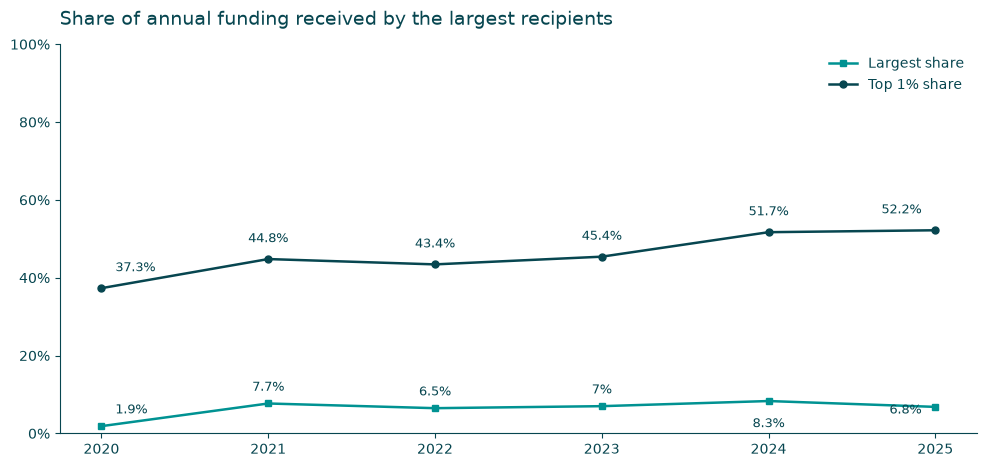

**Finding for 2025:** The median recorded funding was 603.64 EUR; the middle half lay approximately between 229.78 EUR and 1,377.32 EUR. The 155 recipients meeting the positive-funding top-1% threshold received 52.2% of annual funding. This describes concentration, not its cause.

In [7]:
from IPython.display import Markdown
from html import escape
import textwrap

def show_table(table, money=(), percent=()):
    formats = {c: euros for c in money}
    formats.update({c: '{:.1%}' for c in percent})
    for c in table:
        if c not in formats and pd.api.types.is_integer_dtype(table[c]):
            formats[c] = '{:,}'
    display(table.style.format(formats, na_rep='Unavailable', escape='html').hide(axis='index'))

funding_rows = []
for year, frame in annual.groupby('tax_year'):
    values = frame['amount'].dropna()
    positive = values.loc[values.gt(0)]
    threshold = positive.quantile(.99)
    top = values.loc[values.ge(threshold)] if pd.notna(threshold) else values.iloc[:0]
    total = complete_total(frame['amount'])
    denominator = total if pd.notna(total) and total > 0 else np.nan
    funding_rows.append({'Year': year, 'Recorded recipients': len(frame),
        'Known funding': len(values), 'P25': values.quantile(.25), 'Median': values.median(),
        'P75': values.quantile(.75), 'P90': values.quantile(.9), 'Total': total,
        'Top threshold': threshold, 'Top recipients': len(top),
        'Largest share': values.max()/denominator,
        'Top 1% share': top.sum()/denominator})
funding_distribution = pd.DataFrame(funding_rows)
show_table(funding_distribution, money=['P25', 'Median', 'P75', 'P90', 'Total', 'Top threshold'],
           percent=['Largest share', 'Top 1% share'])
fig, ax = plt.subplots(figsize=(10, 5))
for column, color, marker in [('Largest share', CHART_COLORS['secondary'], 's'),
                              ('Top 1% share', CHART_COLORS['primary'], 'o')]:
    ax.plot(funding_distribution.Year, funding_distribution[column], label=column, color=color, marker=marker)
ax.set_title('Share of annual funding received by the largest recipients')
ax.set_xticks(YEARS)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:.0%}'))
ax.grid(False, which='both')
ax.legend(frameon=False)
finish_chart(fig)
r = funding_distribution.loc[funding_distribution.Year.eq(END)].iloc[0]
display(Markdown(f"**Finding for {END}:** The median recorded funding was {euros(r['Median'])}; "
    f"the middle half lay approximately between {euros(r['P25'])} and {euros(r['P75'])}. "
    f"The {int(r['Top recipients']):,} recipients meeting the positive-funding top-1% threshold "
    f"received {r['Top 1% share']:.1%} of annual funding. This describes concentration, not its cause."))

## How do recipient and funding shares differ by funding size?

Recipients are grouped by their **total recorded funding within each year**, using the same euro boundaries throughout 2020-2025. The first chart shows each group's share of recipients; the second shows its share of funding. A group can contain many recipients but account for little funding, or the reverse.

The five funding-size groups are:

| Group | Annual funding |
| --- | --- |
| Very small | 0-1,000 EUR |
| Small | Over 1,000 to 10,000 EUR |
| Medium | Over 10,000 to 50,000 EUR |
| Large | Over 50,000 to 100,000 EUR |
| Very large | Over 100,000 EUR |

Upper boundaries are included, so exactly 1,000 EUR belongs to Very small and exactly 50,000 EUR belongs to Medium. Recorded zeros are included in Very small. Missing amounts remain a separate Unknown group, never zero. Recipient shares include all recorded recipients; funding shares require complete annual amounts and a positive annual total.

Groups are reassigned each year, so changing shares do not by themselves show growth in the same organizations. Boundaries are nominal and are not adjusted for inflation. Segment labels are shown from 3% upward; the table retains smaller shares and exact counts.


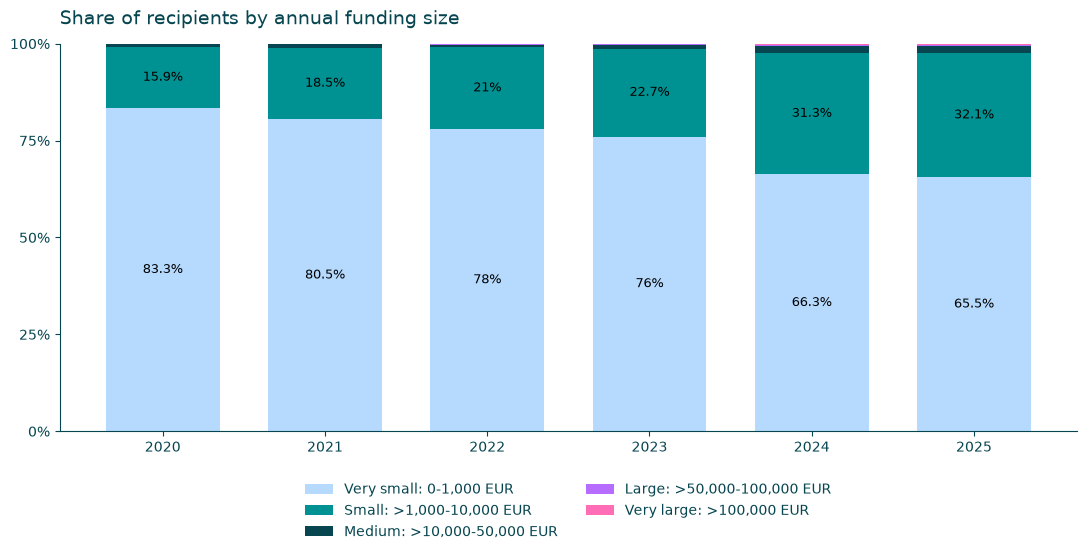

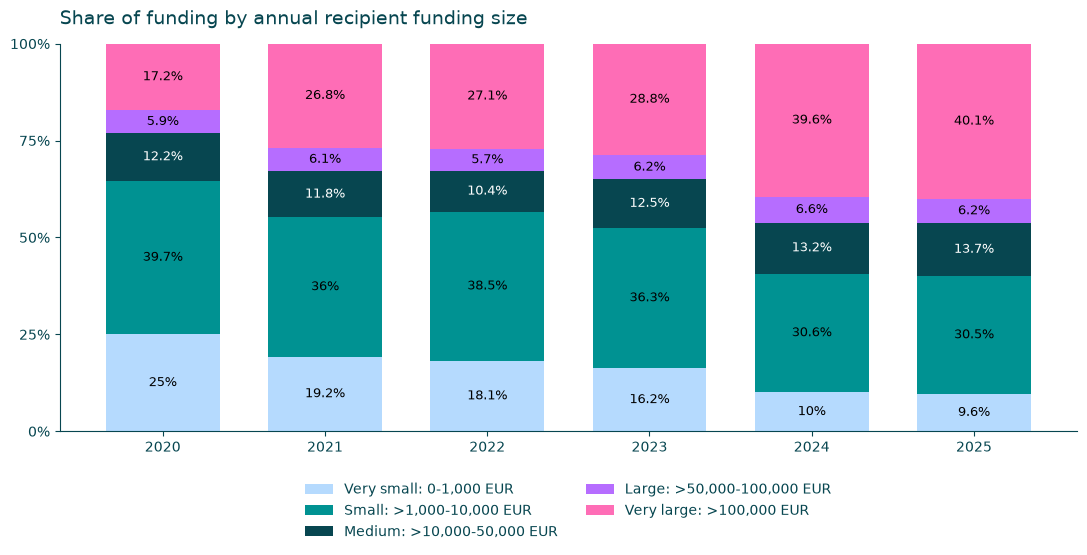

Year,Funding group,Recipients,Funding,Recipient share,Funding share
"2,020",Very small,"19,366","5,410,329.25 EUR",83.3%,25.0%
"2,020",Small,"3,689","8,587,716.58 EUR",15.9%,39.7%
"2,020",Medium,148,"2,649,481.88 EUR",0.6%,12.2%
"2,020",Large,19,"1,283,548.56 EUR",0.1%,5.9%
"2,020",Very large,18,"3,723,676.92 EUR",0.1%,17.2%
"2,021",Very small,"18,344","5,355,884.27 EUR",80.5%,19.2%
"2,021",Small,"4,226","10,014,924.6 EUR",18.5%,36.0%
"2,021",Medium,179,"3,294,197.98 EUR",0.8%,11.8%
"2,021",Large,25,"1,703,486.77 EUR",0.1%,6.1%
"2,021",Very large,24,"7,474,682.24 EUR",0.1%,26.8%


**What stands out in 2025:** Recipients with up to 1,000 EUR, including zeros, made up 65.5% of recorded recipients but received 9.6% of funding. Recipients above 100,000 EUR made up 0.3% of recipients and received 40.1% of funding. The annual bars show whether these shares changed; they do not track the same recipients within each group.

In [8]:
from chart_style import contrast_text

SIZE_GROUPS = ['Very small', 'Small', 'Medium', 'Large', 'Very large', 'Unknown']
SIZE_LABELS = dict(zip(SIZE_GROUPS, [
    'Very small: 0-1,000 EUR', 'Small: >1,000-10,000 EUR',
    'Medium: >10,000-50,000 EUR', 'Large: >50,000-100,000 EUR',
    'Very large: >100,000 EUR', 'Unknown']))

def funding_size_group(amounts):
    if (amounts.dropna().lt(0) | ~np.isfinite(amounts.dropna())).any():
        raise ValueError('Funding size groups require nonnegative, finite amounts.')
    groups = pd.cut(amounts, bins=[-np.inf, 1_000, 10_000, 50_000, 100_000, np.inf],
                    labels=SIZE_GROUPS[:-1], right=True)
    return groups.cat.add_categories(['Unknown']).fillna('Unknown')

assert not annual.duplicated(['recipient_code', 'tax_year']).any()
size_data = annual[['recipient_code', 'tax_year', 'amount']].copy()
size_data['Funding group'] = funding_size_group(size_data['amount'])
size_rows = []
for year in YEARS:
    frame = size_data.loc[size_data.tax_year.eq(year)]
    total = complete_total(frame.amount)
    for group in SIZE_GROUPS:
        members = frame.loc[frame['Funding group'].eq(group)]
        funding = (np.nan if group == 'Unknown' else members.amount.sum())
        size_rows.append({'Year': year, 'Funding group': group,
                         'Recipients': len(members), 'Funding': funding,
                         'Recipient share': len(members) / len(frame) if len(frame) else np.nan,
                         'Funding share': funding / total if pd.notna(total) and total > 0 else np.nan})
funding_size_summary = pd.DataFrame(size_rows)
group_colors = dict(zip(SIZE_GROUPS, ['#b5dafe', '#009292', '#074650', '#b66dff', '#fe6db6', '#777777']))
# Palette entries come directly from the shared theme.
for group, index in zip(SIZE_GROUPS[:-1], [6, 1, 0, 5, 2]):
    group_colors[group] = style['dataColors'][index]

for measure, title in [('Recipient share', 'Share of recipients by annual funding size'),
                       ('Funding share', 'Share of funding by annual recipient funding size')]:
    shares = funding_size_summary.pivot(index='Year', columns='Funding group', values=measure).reindex(YEARS)
    groups = SIZE_GROUPS if measure == 'Recipient share' else SIZE_GROUPS[:-1]
    fig, ax = plt.subplots(figsize=(11, 6))
    bottom = np.zeros(len(YEARS))
    for group in groups:
        values = shares[group].to_numpy(dtype=float)
        if not np.nansum(values) > 0:
            continue
        ax.bar(YEARS, values, bottom=bottom, width=.7, color=group_colors[group],
               edgecolor='none', label=SIZE_LABELS[group])
        for year, value, base in zip(YEARS, values, bottom):
            if np.isfinite(value) and value >= .03:
                ax.text(year, base + value / 2, f'{value:.1%}', ha='center', va='center',
                        fontsize=9, color=contrast_text(group_colors[group]))
        bottom += np.nan_to_num(values)
    for year, row in shares[groups].iterrows():
        if row.isna().all():
            ax.text(year, .5, 'Unavailable', rotation=90, ha='center', va='center')
    ax.set_title(title)
    ax.set_xticks(YEARS)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, .25, .5, .75, 1])
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, pos: f'{value:.0%}'))
    ax.grid(False, which='both')
    ax.legend(loc='upper center', bbox_to_anchor=(.5, -.10), ncol=2, frameon=False)
    finish_chart(fig)

show_table(funding_size_summary.loc[funding_size_summary['Funding group'].ne('Unknown') |
                                  funding_size_summary.Recipients.gt(0)],
           money=['Funding'], percent=['Recipient share', 'Funding share'])

# Boundary and reconciliation checks include missing values and exact upper limits.
assert funding_size_group(pd.Series([0, .01, 1000, 1000.01, 10000, 10000.01,
                                    50000, 50000.01, 100000, 100000.01, np.nan])).tolist() == [
    SIZE_GROUPS[i] for i in [0, 0, 0, 1, 1, 2, 2, 3, 3, 4, 5]]
for year, frame in size_data.groupby('tax_year'):
    result = funding_size_summary.loc[funding_size_summary.Year.eq(year)]
    assert result.Recipients.sum() == len(frame)
    np.testing.assert_allclose(result['Recipient share'].sum(), 1)
    known = result.loc[result['Funding group'].ne('Unknown')]
    np.testing.assert_allclose(known.Funding.sum(), frame.amount.sum())
    if frame.amount.notna().all() and frame.amount.sum() > 0:
        np.testing.assert_allclose(known['Funding share'].sum(), 1)

size_export = PROJECT_ROOT / 'outputs/all_recipients_growth/investigations/annual_funding_size_groups.csv'
size_export.parent.mkdir(parents=True, exist_ok=True)
funding_size_summary.to_csv(size_export, index=False, encoding='utf-8-sig')
latest = funding_size_summary.loc[funding_size_summary.Year.eq(END)]
small = latest.loc[latest['Funding group'].eq('Very small')]
large = latest.loc[latest['Funding group'].eq(SIZE_GROUPS[4])].iloc[0]
if latest['Funding share'].notna().any():
    display(Markdown(f"**What stands out in {END}:** Recipients with up to 1,000 EUR, including zeros, "
        f"made up {small['Recipient share'].sum():.1%} of recorded recipients but received "
        f"{small['Funding share'].sum():.1%} of funding. Recipients above 100,000 EUR made up "
        f"{large['Recipient share']:.1%} of recipients and received {large['Funding share']:.1%} of funding. "
        "The annual bars show whether these shares changed; they do not track the same recipients within each group."))


## How is funding growth distributed across recipients?

Each comparison includes recipients with known funding at both endpoints. Euro changes include zero starting amounts; percentage changes require positive starting funding. Declines and unchanged cases remain visible. Gross gains add positive changes, gross losses add negative changes, and their sum is net change within the matched sample, not the full population's total change. The top ten gainers' share uses gross gains, avoiding unstable shares of a small net change.

Period,Matched recipients,Valid percentage growth,Increasing share,Decreasing share,Unchanged share,P25 euro change,Median euro change,P75 euro change,Gross gains,Gross losses,Net change,Top ten share of gains
2020-2021,"20,974","20,908",58.9%,41.1%,0.1%,-48.23 EUR,13.87 EUR,122.95 EUR,"7,642,254.8 EUR","-1,993,981.34 EUR","5,648,273.46 EUR",41.8%
2021-2022,"20,278","20,222",54.7%,45.1%,0.1%,-82.19 EUR,9.32 EUR,126.38 EUR,"4,644,367.03 EUR","-3,593,969.9 EUR","1,050,397.13 EUR",14.7%
2022-2023,"19,999","19,931",55.9%,44.0%,0.1%,-89.68 EUR,12.58 EUR,148.52 EUR,"6,531,338.26 EUR","-2,868,990.82 EUR","3,662,347.44 EUR",23.7%
2023-2024,"12,668","12,632",66.2%,33.7%,0.0%,-50.77 EUR,88.11 EUR,385.57 EUR,"10,322,099.38 EUR","-1,763,988.16 EUR","8,558,111.22 EUR",30.4%
2024-2025,"13,414","13,375",54.1%,45.9%,0.0%,-166.48 EUR,16.26 EUR,232.3 EUR,"5,857,474.14 EUR","-3,918,872.92 EUR","1,938,601.22 EUR",19.0%
2020-2025,"10,408","10,381",70.1%,29.9%,0.0%,-39.78 EUR,183.53 EUR,653.46 EUR,"19,579,968.09 EUR","-2,165,912.59 EUR","17,414,055.5 EUR",39.8%


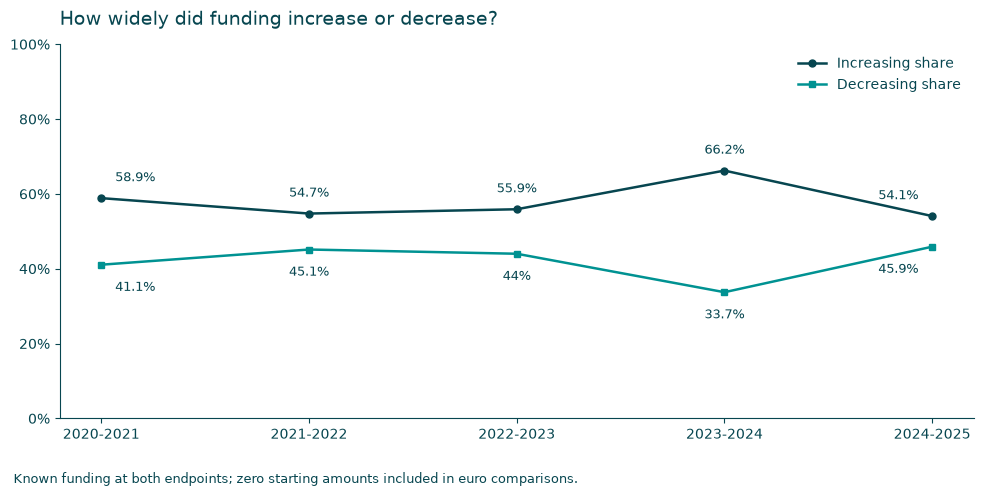

**Latest annual comparison:** Among 13,414 matched recipients, 54.1% gained funding and 45.9% lost funding. The median euro change was 16.26 EUR. The ten largest gains represented 19.0% of gross gains; losses are reported separately.

In [9]:
names = fixed.set_index('recipient_code')['recipient_name']
endpoint_pairs = {}
spread_rows = []
for start, end in [(y-1, y) for y in YEARS[1:]] + [(START, END)]:
    key = f'{start}-{end}'
    pair = funding_matrix[[start, end]].dropna().rename(columns={start: 'Start funding', end: 'End funding'})
    pair['Euro change'] = pair['End funding'] - pair['Start funding']
    pair['Percentage change'] = pair['Euro change'] / pair['Start funding'].where(pair['Start funding'] > 0)
    pair['Recipient'] = pair.index.map(names)
    endpoint_pairs[key] = pair
    change = pair['Euro change']
    gains = change.loc[change > 0]
    losses = change.loc[change < 0]
    gross = gains.sum()
    spread_rows.append({'Period': key, 'Matched recipients': len(pair),
        'Valid percentage growth': pair['Percentage change'].count(),
        'Increasing share': change.gt(0).mean(), 'Decreasing share': change.lt(0).mean(),
        'Unchanged share': change.eq(0).mean(), 'P25 euro change': change.quantile(.25),
        'Median euro change': change.median(), 'P75 euro change': change.quantile(.75),
        'Gross gains': gross, 'Gross losses': losses.sum(), 'Net change': change.sum(),
        'Top ten share of gains': gains.nlargest(10).sum()/gross if gross > 0 else np.nan})
growth_spread = pd.DataFrame(spread_rows)
show_table(growth_spread, money=['P25 euro change', 'Median euro change', 'P75 euro change',
    'Gross gains', 'Gross losses', 'Net change'], percent=[c for c in growth_spread if 'share' in c.lower()])
fig, ax = plt.subplots(figsize=(10, 5))
plot_spread = growth_spread.iloc[:-1]
for c, color, marker in [('Increasing share', CHART_COLORS['primary'], 'o'),
                         ('Decreasing share', CHART_COLORS['secondary'], 's')]:
    ax.plot(plot_spread.Period, plot_spread[c], label=c, color=color, marker=marker)
ax.set_title('How widely did funding increase or decrease?')
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:.0%}'))
ax.grid(False, which='both')
ax.legend(frameon=False)
finish_chart(fig, 'Known funding at both endpoints; zero starting amounts included in euro comparisons.')
r = growth_spread.loc[growth_spread.Period.eq(f'{END-1}-{END}')].iloc[0]
display(Markdown(f"**Latest annual comparison:** Among {int(r['Matched recipients']):,} matched recipients, "
    f"{r['Increasing share']:.1%} gained funding and {r['Decreasing share']:.1%} lost funding. "
    f"The median euro change was {euros(r['Median euro change'])}. The ten largest gains represented "
    f"{r['Top ten share of gains']:.1%} of gross gains; losses are reported separately."))

## Which recipients grew substantially?

There is no universal definition of substantial growth. The first ranking shows the largest euro increases without a minimum starting amount. A separate, adjustable screen requires at least EUR 1,000 at the start, at least 100% growth, and a euro gain at or above the 90th percentile of positive gains in that comparison. These are exploratory criteria, not significance tests. Full qualifying lists retain ties; previews show at most ten recipients. The latest annual pair and fixed 2020-2025 period are shown separately.

In [10]:
MIN_START_FUNDING = 1000
MIN_GROWTH = 1.0
GAIN_QUANTILE = .90
growth_rankings = []
substantial_lists = []
for period in [f'{END-1}-{END}', f'{START}-{END}']:
    pair = endpoint_pairs[period].copy()
    positive_gains = pair.loc[pair['Euro change'] > 0, 'Euro change']
    cutoff = positive_gains.quantile(GAIN_QUANTILE)
    pair['Period'] = period
    pair['Substantial growth'] = (pair['Start funding'].ge(MIN_START_FUNDING)
        & pair['Percentage change'].ge(MIN_GROWTH) & pair['Euro change'].ge(cutoff))
    ranked = pair.sort_values(['Euro change', 'Recipient'], ascending=[False, True]).reset_index()
    growth_rankings.append(ranked)
    substantial = ranked.loc[ranked['Substantial growth']].copy()
    substantial_lists.append(substantial)
    cols = ['recipient_code', 'Recipient', 'Start funding', 'End funding', 'Euro change', 'Percentage change']
    print(f'{period}: largest euro gains')
    show_table(ranked.loc[ranked['Euro change'] > 0, cols].head(10),
               money=['Start funding', 'End funding', 'Euro change'], percent=['Percentage change'])
    print(f'{period}: {len(substantial):,} recipients meet the screen; euro-gain threshold {euros(cutoff)}')
    show_table(substantial[cols].head(10), money=['Start funding', 'End funding', 'Euro change'], percent=['Percentage change'])
    leader = ranked.loc[ranked['Euro change'] > 0].head(1)
    if not leader.empty:
        r = leader.iloc[0]
        display(Markdown(f"**Largest euro gain in {period}:** {escape(str(r['Recipient']))} "
            f"(code {r['recipient_code']}) gained {euros(r['Euro change'])}. "
            "This ranking measures absolute change, not supporter generosity or causal success."))

2024-2025: largest euro gains


recipient_code,Recipient,Start funding,End funding,Euro change,Percentage change
302721009,Rimanto Kaukėno paramos grupė,"1,287,248.9 EUR","1,471,194.93 EUR","183,946.03 EUR",14.3%
305017992,"VšĮ ""Savanoriai vaikams""","849,427.46 EUR","1,016,991.27 EUR","167,563.81 EUR",19.7%
301753623,Tėvynės sąjunga-Lietuvos krikščionys demokratai,"1,048,637.38 EUR","1,176,651.17 EUR","128,013.79 EUR",12.2%
190740859,Maltos ordino pagalbos tarnyba,"496,482.17 EUR","613,820.81 EUR","117,338.64 EUR",23.6%
306728905,Maltiečių paramos fondas,"78,181.5 EUR","178,427.93 EUR","100,246.43 EUR",128.2%
302704554,Pagalbos onkologiniams ligoniams asociacija,"257,375.32 EUR","351,558.79 EUR","94,183.47 EUR",36.6%
303211621,"VšĮ Tiriamosios žurnalistikos centras ""Siena""","50,960.42 EUR","143,854.25 EUR","92,893.83 EUR",182.3%
305706699,"VšĮ ""Tiesa yra svarbu""","363,799.09 EUR","455,919.29 EUR","92,120.2 EUR",25.3%
304405807,Laisvės TV,"376,355.41 EUR","456,623.99 EUR","80,268.58 EUR",21.3%
300559448,Liberalų sąjūdis,"285,437.6 EUR","343,690.3 EUR","58,252.7 EUR",20.4%


2024-2025: 138 recipients meet the screen; euro-gain threshold 1,107.7 EUR


recipient_code,Recipient,Start funding,End funding,Euro change,Percentage change
306728905,Maltiečių paramos fondas,"78,181.5 EUR","178,427.93 EUR","100,246.43 EUR",128.2%
303211621,"VšĮ Tiriamosios žurnalistikos centras ""Siena""","50,960.42 EUR","143,854.25 EUR","92,893.83 EUR",182.3%
162939779,"Asociacija ""Ekosistemų apsaugos centras""","8,231.21 EUR","54,106.6 EUR","45,875.39 EUR",557.3%
305801574,"VšĮ ""Rimanto Kaukėno paramos fondo hospisas""","33,468.06 EUR","73,843.9 EUR","40,375.84 EUR",120.6%
300556352,Vilniaus licėjaus labdaros ir paramos fondas,"32,346.37 EUR","68,076.83 EUR","35,730.46 EUR",110.5%
306302421,"VšĮ ""Lakis"" gyvūnų globa ir gydymas","7,888.65 EUR","37,738.53 EUR","29,849.88 EUR",378.4%
306348251,"Viešoji įstaiga ""Vilnelės šeimos klinika""","19,498.45 EUR","47,791.2 EUR","28,292.75 EUR",145.1%
304499272,Kupiškio aeroklubas,"4,149.48 EUR","29,979.14 EUR","25,829.66 EUR",622.5%
306644955,"Asociacija ""Avela racing team""","19,336.31 EUR","41,900.85 EUR","22,564.54 EUR",116.7%
307119572,Liepos Venytės labdaros ir paramos fondas,"16,821.43 EUR","35,756.38 EUR","18,934.95 EUR",112.6%


**Largest euro gain in 2024-2025:** Rimanto Kaukėno paramos grupė (code 302721009) gained 183,946.03 EUR. This ranking measures absolute change, not supporter generosity or causal success.

2020-2025: largest euro gains


recipient_code,Recipient,Start funding,End funding,Euro change,Percentage change
303420560,"VšĮ ""Mėlyna ir geltona""","18,091.51 EUR","2,732,929.35 EUR","2,714,837.84 EUR",15006.1%
302721009,Rimanto Kaukėno paramos grupė,"357,125.44 EUR","1,471,194.93 EUR","1,114,069.49 EUR",312.0%
305017992,"VšĮ ""Savanoriai vaikams""","171,503.52 EUR","1,016,991.27 EUR","845,487.75 EUR",493.0%
301753623,Tėvynės sąjunga-Lietuvos krikščionys demokratai,"347,727.46 EUR","1,176,651.17 EUR","828,923.71 EUR",238.4%
302288579,"Paramos ir labdaros fondas ""Mamų unija""","402,650.06 EUR","1,003,965.2 EUR","601,315.14 EUR",149.3%
305706699,"VšĮ ""Tiesa yra svarbu""","53,748.2 EUR","455,919.29 EUR","402,171.09 EUR",748.3%
301536872,"Viešoji įstaiga ""SOS GYVŪNAI""","90,582.02 EUR","424,532.23 EUR","333,950.21 EUR",368.7%
301536790,"VšĮ ""PENKTA KOJA""","224,009.53 EUR","545,210.16 EUR","321,200.63 EUR",143.4%
190740859,Maltos ordino pagalbos tarnyba,"301,336.42 EUR","613,820.81 EUR","312,484.39 EUR",103.7%
302704554,Pagalbos onkologiniams ligoniams asociacija,"41,626.37 EUR","351,558.79 EUR","309,932.42 EUR",744.6%


2020-2025: 358 recipients meet the screen; euro-gain threshold 2,176.49 EUR


recipient_code,Recipient,Start funding,End funding,Euro change,Percentage change
303420560,"VšĮ ""Mėlyna ir geltona""","18,091.51 EUR","2,732,929.35 EUR","2,714,837.84 EUR",15006.1%
302721009,Rimanto Kaukėno paramos grupė,"357,125.44 EUR","1,471,194.93 EUR","1,114,069.49 EUR",312.0%
305017992,"VšĮ ""Savanoriai vaikams""","171,503.52 EUR","1,016,991.27 EUR","845,487.75 EUR",493.0%
301753623,Tėvynės sąjunga-Lietuvos krikščionys demokratai,"347,727.46 EUR","1,176,651.17 EUR","828,923.71 EUR",238.4%
302288579,"Paramos ir labdaros fondas ""Mamų unija""","402,650.06 EUR","1,003,965.2 EUR","601,315.14 EUR",149.3%
305706699,"VšĮ ""Tiesa yra svarbu""","53,748.2 EUR","455,919.29 EUR","402,171.09 EUR",748.3%
301536872,"Viešoji įstaiga ""SOS GYVŪNAI""","90,582.02 EUR","424,532.23 EUR","333,950.21 EUR",368.7%
301536790,"VšĮ ""PENKTA KOJA""","224,009.53 EUR","545,210.16 EUR","321,200.63 EUR",143.4%
190740859,Maltos ordino pagalbos tarnyba,"301,336.42 EUR","613,820.81 EUR","312,484.39 EUR",103.7%
302704554,Pagalbos onkologiniams ligoniams asociacija,"41,626.37 EUR","351,558.79 EUR","309,932.42 EUR",744.6%


**Largest euro gain in 2020-2025:** VšĮ &quot;Mėlyna ir geltona&quot; (code 303420560) gained 2,714,837.84 EUR. This ranking measures absolute change, not supporter generosity or causal success.

## Which recipients have unusually high funding per request?

High means at or above that year's 95th percentile of all valid recipient averages, including zeros; ties are retained. These are average amounts per request for organizations, not individual requests or supporter incomes. The unfiltered upper tail is shown first. A separate credibility screen requires at least ten requests in that year, an adjustable safeguard against averages based on very few requests. It is not a formal reliability test. The percentile benchmark is not recalculated after this screen.

In [11]:
MIN_RATIO_REQUESTS = 10
ratio_records = annual.loc[annual['amount'].notna() & annual.requests.gt(0)].copy()
ratio_records['ratio'] = ratio_records.amount / ratio_records.requests
ratio_benchmarks = ratio_records.groupby('tax_year').ratio.quantile(.95)
ratio_records['annual_p95'] = ratio_records.tax_year.map(ratio_benchmarks)
ratio_records['high_ratio'] = ratio_records.ratio.ge(ratio_records.annual_p95)
ratio_records['screened_high'] = ratio_records.high_ratio & ratio_records.requests.ge(MIN_RATIO_REQUESTS)
ratio_tail = ratio_records.groupby('tax_year').agg(
    valid_recipients=('recipient_code', 'nunique'), p95=('annual_p95', 'first'),
    high_recipients=('high_ratio', 'sum'), screened_high_recipients=('screened_high', 'sum'))
show_table(ratio_tail.reset_index(), money=['p95'])
latest_high = ratio_records.loc[ratio_records.tax_year.eq(END) & ratio_records.high_ratio].sort_values(
    ['ratio', 'recipient_code'], ascending=[False, True])
cols = ['recipient_code', 'recipient_name', 'amount', 'requests', 'ratio', 'annual_p95']
print(f'{END}: highest recipient averages, without a minimum-request screen')
show_table(latest_high[cols].head(10), money=['amount', 'ratio', 'annual_p95'])
screened_high = latest_high.loc[latest_high.screened_high].copy()
print(f'{END}: high averages with at least {MIN_RATIO_REQUESTS} requests')
show_table(screened_high[cols].head(10), money=['amount', 'ratio', 'annual_p95'])
display(Markdown(f"**Latest-year result:** {len(latest_high):,} recipients meet the P95 threshold of "
    f"{euros(ratio_benchmarks.loc[END])}; {len(screened_high):,} also have at least {MIN_RATIO_REQUESTS} requests. "
    "The two rankings show how much the interpretation depends on request volume."))

tax_year,valid_recipients,p95,high_recipients,screened_high_recipients
"2,020","23,233",109.53 EUR,"1,162",192
"2,021","22,779",126.56 EUR,"1,139",202
"2,022","22,128",143.59 EUR,"1,107",192
"2,023","22,535",154.82 EUR,"1,127",175
"2,024","14,501",185.99 EUR,726,118
"2,025","15,483",168.95 EUR,775,111


2025: highest recipient averages, without a minimum-request screen


recipient_code,recipient_name,amount,requests,ratio,annual_p95
305227713,"Viešoji įstaiga ""Rado - rodo""","41,212.21 EUR",2,"20,606.1 EUR",168.95 EUR
306348251,"Viešoji įstaiga ""Vilnelės šeimos klinika""","47,791.2 EUR",3,"15,930.4 EUR",168.95 EUR
307138195,"Asociacija ""Jūrai.lt""","26,009.9 EUR",2,"13,004.95 EUR",168.95 EUR
305618295,"VšĮ ""Adomo Galdiko muziejus ir menų mokykla""","10,609.8 EUR",2,"5,304.9 EUR",168.95 EUR
302335751,"Viešoji įstaiga ""Gačionių dvaras""","4,155.44 EUR",1,"4,155.44 EUR",168.95 EUR
305117964,"VšĮ ""Padūmio projektai""","35,608.49 EUR",9,"3,956.5 EUR",168.95 EUR
304802367,VšĮ Vairuotojų kvalifikacinio rengimo centras,"3,745.82 EUR",1,"3,745.82 EUR",168.95 EUR
306678555,VšĮ Dr Jauniaus Gumbio Lietuvos meno fondas,"7,139.55 EUR",2,"3,569.78 EUR",168.95 EUR
303498000,"VšĮ ""Olimpinė viltis""","3,269.95 EUR",1,"3,269.95 EUR",168.95 EUR
305701499,"Viešoji įstaiga ""Žaliasis kursas""","6,145.85 EUR",2,"3,072.93 EUR",168.95 EUR


2025: high averages with at least 10 requests


recipient_code,recipient_name,amount,requests,ratio,annual_p95
302633630,"Visuomeninė organizacija ""Darni Plungė""","18,383.14 EUR",13,"1,414.09 EUR",168.95 EUR
307086275,VšĮ We Roll Together,"8,891.59 EUR",11,808.33 EUR,168.95 EUR
302455793,VšĮ Suosių medžiotojų klubas,"11,124.74 EUR",14,794.62 EUR,168.95 EUR
306269213,"VšĮ ""Mėlynai geltonas lašelis""","21,038.81 EUR",33,637.54 EUR,168.95 EUR
307649186,Sollo foundation paramos fondas,"5,336.94 EUR",10,533.69 EUR,168.95 EUR
302532357,Akmenės rajono Sprogiškės medžiotojų klubas,"7,274.82 EUR",14,519.63 EUR,168.95 EUR
126157052,VILNIAUS ŠV. KRISTOFORO ROTARY KLUBAS,"5,910.57 EUR",12,492.55 EUR,168.95 EUR
304075843,"VšĮ Šaudymo sporto klubas ""Aštuntojo būrio šauliai""","34,675.18 EUR",71,488.38 EUR,168.95 EUR
307003393,"VšĮ ""Dainavos gamtos fondas""","6,223.49 EUR",13,478.73 EUR,168.95 EUR
305540793,VšĮ Sporto ir sveikatingumo projektai,"23,770.51 EUR",50,475.41 EUR,168.95 EUR


**Latest-year result:** 775 recipients meet the P95 threshold of 168.95 EUR; 111 also have at least 10 requests. The two rankings show how much the interpretation depends on request volume.

## Do high funding-per-request averages persist over time?

These histories follow the same five recipients with the highest screened averages in the final year. Selection is based on 2025, so it favors recipients observed then and is not representative of all recipients or all past leaders. Full histories retain missing years as gaps and show request counts alongside amounts. The annual median and P95 provide changing population benchmarks. A valid high-average year and a high-average year meeting the minimum-request screen are counted separately.

recipient_code,Recipient,recorded_years,valid_ratio_years,high_years,screened_high_years,minimum_requests,maximum_requests
302455793,VšĮ Suosių medžiotojų klubas,6,6,6,1,4,14
302633630,"Visuomeninė organizacija ""Darni Plungė""",6,6,5,3,4,13
306269213,"VšĮ ""Mėlynai geltonas lašelis""",4,4,3,3,12,33
307086275,VšĮ We Roll Together,2,2,1,1,11,12
307649186,Sollo foundation paramos fondas,1,1,1,1,10,10


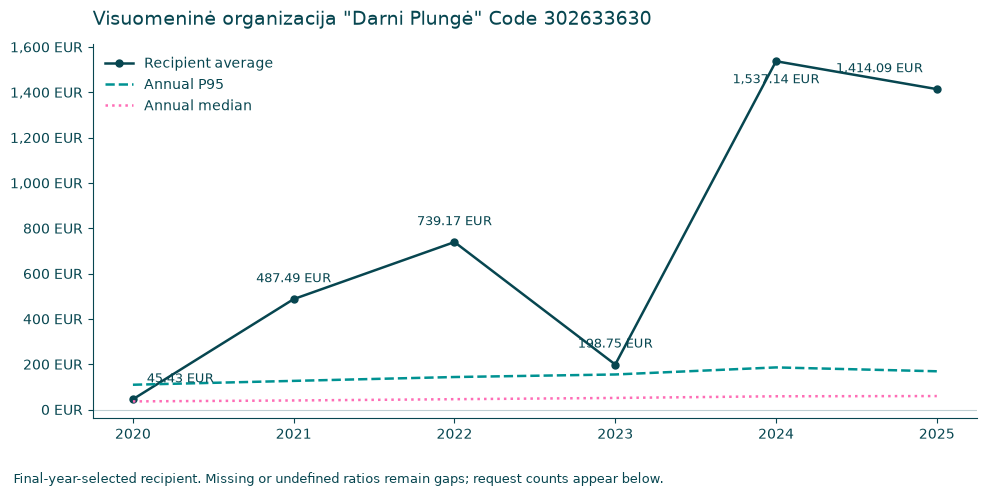

tax_year,amount,requests,ratio,annual_p95
"2,020",272.56 EUR,6,45.43 EUR,109.53 EUR
"2,021","4,874.9 EUR",10,487.49 EUR,126.56 EUR
"2,022","7,391.71 EUR",10,739.17 EUR,143.59 EUR
"2,023",795 EUR,4,198.75 EUR,154.82 EUR
"2,024","10,759.99 EUR",7,"1,537.14 EUR",185.99 EUR
"2,025","18,383.14 EUR",13,"1,414.09 EUR",168.95 EUR


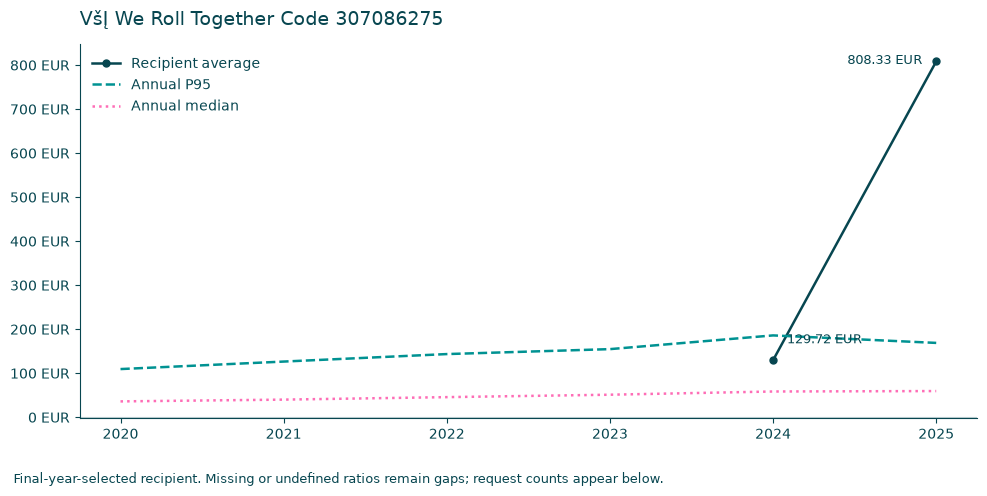

tax_year,amount,requests,ratio,annual_p95
"2,020",Unavailable,Unavailable,Unavailable,Unavailable
"2,021",Unavailable,Unavailable,Unavailable,Unavailable
"2,022",Unavailable,Unavailable,Unavailable,Unavailable
"2,023",Unavailable,Unavailable,Unavailable,Unavailable
"2,024","1,556.63 EUR",12.000000,129.72 EUR,185.99 EUR
"2,025","8,891.59 EUR",11.000000,808.33 EUR,168.95 EUR


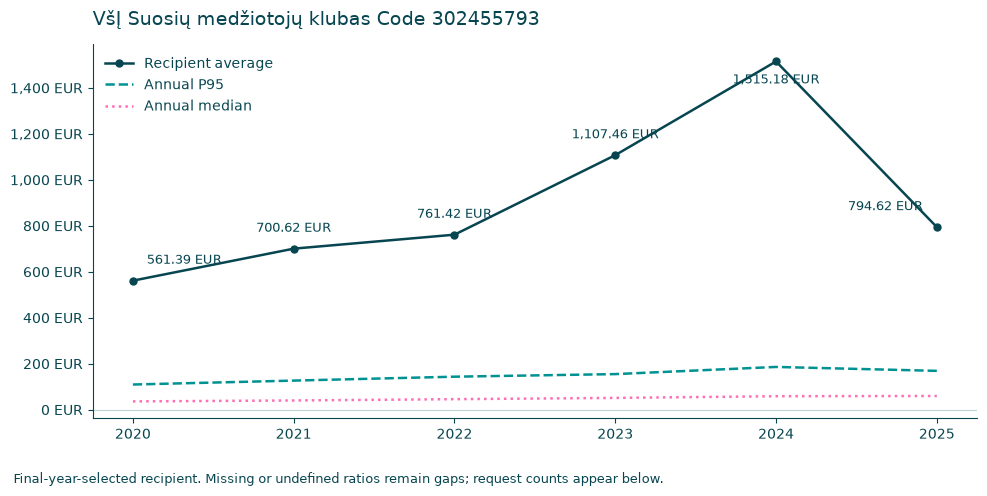

tax_year,amount,requests,ratio,annual_p95
"2,020","2,245.55 EUR",4,561.39 EUR,109.53 EUR
"2,021","4,203.75 EUR",6,700.62 EUR,126.56 EUR
"2,022","6,091.33 EUR",8,761.42 EUR,143.59 EUR
"2,023","9,967.15 EUR",9,"1,107.46 EUR",154.82 EUR
"2,024","13,636.59 EUR",9,"1,515.18 EUR",185.99 EUR
"2,025","11,124.74 EUR",14,794.62 EUR,168.95 EUR


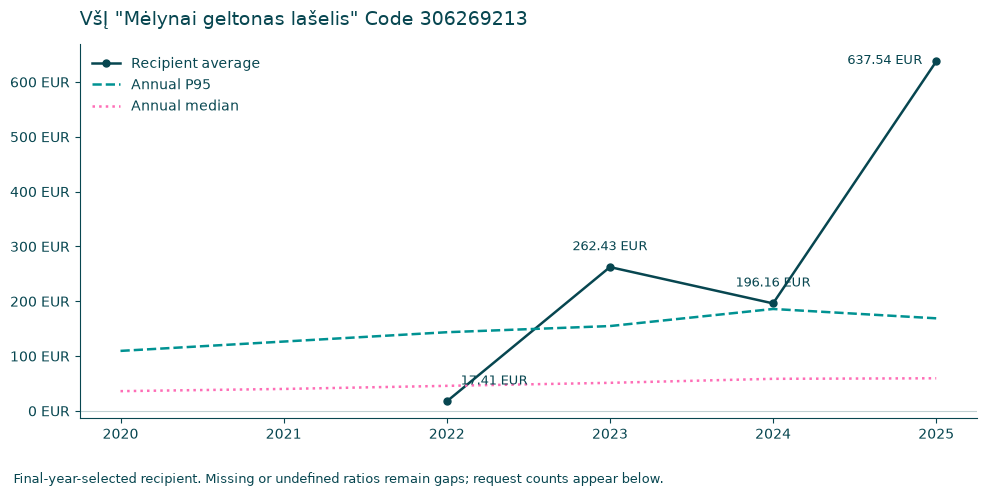

tax_year,amount,requests,ratio,annual_p95
"2,020",Unavailable,Unavailable,Unavailable,Unavailable
"2,021",Unavailable,Unavailable,Unavailable,Unavailable
"2,022",208.95 EUR,12.000000,17.41 EUR,143.59 EUR
"2,023","4,986.18 EUR",19.000000,262.43 EUR,154.82 EUR
"2,024","6,277.26 EUR",32.000000,196.16 EUR,185.99 EUR
"2,025","21,038.81 EUR",33.000000,637.54 EUR,168.95 EUR


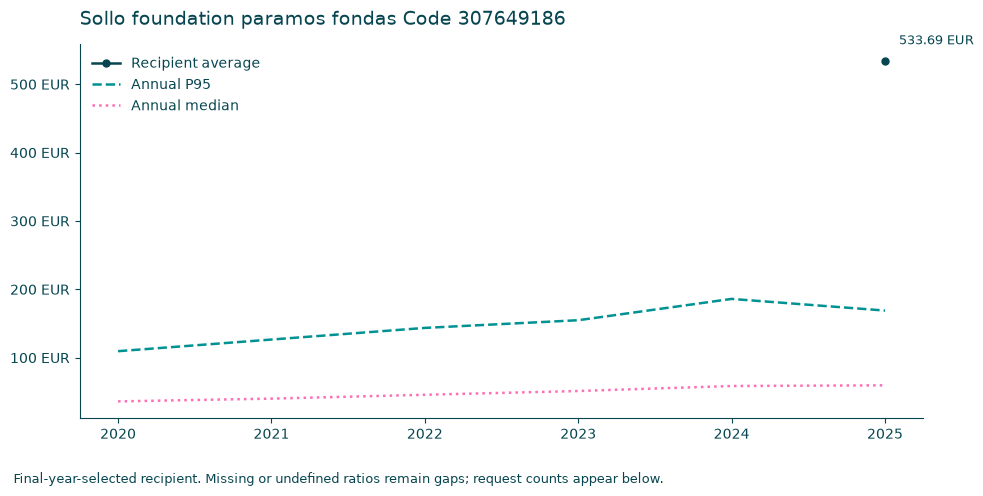

tax_year,amount,requests,ratio,annual_p95
"2,020",Unavailable,Unavailable,Unavailable,Unavailable
"2,021",Unavailable,Unavailable,Unavailable,Unavailable
"2,022",Unavailable,Unavailable,Unavailable,Unavailable
"2,023",Unavailable,Unavailable,Unavailable,Unavailable
"2,024",Unavailable,Unavailable,Unavailable,Unavailable
"2,025","5,336.94 EUR",10.000000,533.69 EUR,168.95 EUR


**Persistence check:** 2 of the 5 displayed final-year leaders met both the annual P95 and minimum-request screen in at least three years. Those years need not be consecutive. Spikes should be read alongside changes in request counts, not interpreted as proof of high supporter incomes.

In [12]:
selected_codes = screened_high.head(5).recipient_code.tolist()
ratio_histories = annual.loc[annual.recipient_code.isin(selected_codes)].copy()
ratio_histories['ratio'] = ratio_histories.amount / ratio_histories.requests.where(ratio_histories.requests > 0)
ratio_histories['annual_p95'] = ratio_histories.tax_year.map(ratio_benchmarks)
ratio_histories['high_year'] = ratio_histories.ratio.ge(ratio_histories.annual_p95)
ratio_histories['screened_high_year'] = ratio_histories.high_year & ratio_histories.requests.ge(MIN_RATIO_REQUESTS)
history_summary = ratio_histories.groupby('recipient_code').agg(
    Recipient=('recipient_name', 'last'), recorded_years=('tax_year', 'nunique'),
    valid_ratio_years=('ratio', 'count'), high_years=('high_year', 'sum'),
    screened_high_years=('screened_high_year', 'sum'),
    minimum_requests=('requests', 'min'), maximum_requests=('requests', 'max')).reset_index()
show_table(history_summary)
median_benchmark = ratio_records.groupby('tax_year').ratio.median().reindex(YEARS)
for code in selected_codes:
    history = ratio_histories.loc[ratio_histories.recipient_code.eq(code)].set_index('tax_year').reindex(YEARS)
    name = str(names.loc[code])
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(YEARS, history.ratio, marker='o', color=CHART_COLORS['primary'], label='Recipient average')
    ax.plot(YEARS, ratio_benchmarks.reindex(YEARS), linestyle='--', color=CHART_COLORS['secondary'], label='Annual P95')
    ax.plot(YEARS, median_benchmark, linestyle=':', color=CHART_COLORS['accent'], label='Annual median')
    ax.set_title(textwrap.fill(name, 65) + f'\nCode {code}')
    ax.set_xticks(YEARS)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: euros(x)))
    ax.grid(False, which='both')
    ax.legend(frameon=False)
    finish_chart(fig, 'Final-year-selected recipient. Missing or undefined ratios remain gaps; request counts appear below.')
    show_table(history[['amount', 'requests', 'ratio', 'annual_p95']].reset_index(), money=['amount', 'ratio', 'annual_p95'])
if len(history_summary):
    sustained = history_summary.screened_high_years.ge(3).sum()
    display(Markdown(f"**Persistence check:** {sustained} of the {len(history_summary)} displayed final-year leaders "
        "met both the annual P95 and minimum-request screen in at least three years. "
        "Those years need not be consecutive. Spikes should be read alongside changes in request counts, not interpreted as proof of high supporter incomes."))

## Full results for the four investigations

These CSV files retain the complete rankings and diagnostic tables. Exported codes remain identifiers. Checks reconcile gains and losses, subgroup counts, and full-population funding totals. The exploratory growth and request-count thresholds are recorded alongside the results.

In [ ]:
investigation_dir = PROJECT_ROOT / 'outputs/all_recipients_growth/investigations'
investigation_dir.mkdir(parents=True, exist_ok=True)
exports = {
    'annual_funding_distribution': funding_distribution,
    'growth_spread': growth_spread,
    'ranked_endpoint_growth': pd.concat(growth_rankings, ignore_index=True),
    'substantial_growth_screen': pd.concat(substantial_lists, ignore_index=True),
    'annual_high_ratio_recipients': ratio_records.loc[ratio_records.high_ratio],
    'latest_high_ratios': latest_high,
    'selected_ratio_histories': ratio_histories,
    'selected_ratio_persistence': history_summary,
}
for filename, table in exports.items():
    table.to_csv(investigation_dir / (filename + '.csv'), index=False, encoding='utf-8-sig')
import json
(investigation_dir / 'definitions.json').write_text(json.dumps({
    'population': 'All recorded recipients; no legal-form filter', 'start': START, 'end': END,
    'minimum_start_funding': MIN_START_FUNDING, 'minimum_percentage_growth': MIN_GROWTH,
    'positive_gain_quantile': GAIN_QUANTILE, 'high_ratio_quantile': .95,
    'minimum_ratio_requests': MIN_RATIO_REQUESTS, 'selected_history_count': len(selected_codes),
    'history_selection_year': END, 'ties': 'Included at percentile thresholds; top previews limited by code order',
}, indent=2), encoding='utf-8')
np.testing.assert_allclose(growth_spread['Gross gains'] + growth_spread['Gross losses'], growth_spread['Net change'])
np.testing.assert_allclose(growth_spread[['Increasing share', 'Decreasing share', 'Unchanged share']].sum(axis=1), 1)
np.testing.assert_allclose(funding_distribution.Total, totals.funding, equal_nan=True)
assert not ratio_records.duplicated(['recipient_code', 'tax_year']).any()
assert screened_high.requests.ge(MIN_RATIO_REQUESTS).all()
assert screened_high.ratio.ge(screened_high.annual_p95).all()
print('Investigation checks passed; full results:', investigation_dir)

## Exported recipient results and checks

Full recipient tables are saved separately rather than embedded in notebook output. Coverage counts reconcile to all recorded recipient codes. These checks validate this notebook only; they do not replace the full project's reproducibility run.

In [ ]:
output_dir = PROJECT_ROOT / 'outputs/all_recipients_growth'
output_dir.mkdir(parents=True, exist_ok=True)
annual.to_csv(output_dir / 'annual_recipient_growth.csv', index=False, encoding='utf-8-sig')
fixed.to_csv(output_dir / 'fixed_period_recipient_growth.csv', index=False, encoding='utf-8-sig')
annual_coverage.to_csv(output_dir / 'annual_coverage.csv', index=False, encoding='utf-8-sig')
assert fixed.recipient_code.nunique() == data.recipient_code.nunique()
assert annual_coverage.groupby('Period').Recipients.sum().eq(len(fixed)).all()
assert annual.loc[annual.year_gap.ne(1), 'yearly_growth_pct'].isna().all()
assert valid_fixed.loc[valid_fixed.endpoint_amount.eq(0), 'fixed_period_growth_pct'].eq(-1).all()
assert pd.isna(complete_total(pd.Series([1., np.nan])))
assert complete_total(pd.Series([0., 1.])) == 1
print('Coverage and growth checks passed. Full tables:', output_dir)

## Reading the results together

Population totals include changing membership. Matched growth describes only recipients with comparable observations, and ratio comparisons require additional request data. A rise in total funding is not evidence that most organizations grew.

The full-population and filtered results answer different questions. Differences from [notebook 07](07_growth_drivers_analysis.ipynb) show sensitivity to legal-form selection; they are not automatically effects caused by an eligibility reform. This notebook does not infer supporter income from recipient averages.

[Funding overview](01_exploratory_analysis.ipynb) | [Filtered growth analysis](07_growth_drivers_analysis.ipynb) | [Project overview](../README.md)